# 1 加载并划分可训练数据集
## 1.1 加载数据并标准化

In [1]:
import scipy.io
from sklearn.preprocessing import StandardScaler


mat = scipy.io.loadmat('Data_sets\MS_NS_TrainData\Features_matrix.mat')
X = mat['Features_matrix']
mat = scipy.io.loadmat('Data_sets\MS_NS_TrainData\Label.mat')
y = mat['Label']

scaler = StandardScaler()
X_resampled = scaler.fit_transform(X)

print(X_resampled.shape)

(10000, 14)


## 1.2 划分训练集、验证集和测试集

In [2]:
from sklearn.model_selection import train_test_split


# 划分数据集，80%训练集, 10%验证集, 10%测试集
X_train, X_temp, y_train, y_temp = train_test_split(X_resampled, y, test_size=0.2, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# 输出划分结果
print("训练集大小:", X_train.shape, y_train.shape)
print("验证集大小:", X_valid.shape, y_valid.shape)
print("测试集大小:", X_test.shape, y_test.shape)

训练集大小: (8000, 14) (8000, 1)
验证集大小: (1000, 14) (1000, 1)
测试集大小: (1000, 14) (1000, 1)


## 1.3 使用SMOTE对训练集进行数据增强

In [3]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

smote = SMOTE(sampling_strategy='auto', random_state=42)
res_Xtrain, res_Ytrain = smote.fit_resample(X_train, y_train)

# 将标签转化为一维数组
res_Ytrain = res_Ytrain.ravel()
y_valid = y_valid.ravel()
y_test = y_test.ravel()

# 标准化数据
# scaler = StandardScaler()
# res_Xtrain = scaler.fit_transform(res_Xtrain)
# X_valid = scaler.transform(X_valid)
# X_test = scaler.transform(X_test)


print(res_Xtrain.shape)

(9606, 14)


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from bayes_opt import BayesianOptimization
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier, Pool
from functools import partial

# ======================
# 自定义焦点损失函数
# ======================
class FocalLoss:
    def __init__(self, alpha=0.25, gamma=2.0):
        self.alpha = alpha
        self.gamma = gamma

    # XGBoost目标函数
    def xgb_fl(self, preds, dmatrix):
        y_true = dmatrix.get_label()
        y_pred = 1.0 / (1.0 + np.exp(-preds))
        pt = np.where(y_true == 1, y_pred, 1 - y_pred)
        grad = (y_pred - y_true) * self.alpha * (1 - pt)**self.gamma
        hess = y_pred * (1 - y_pred) * self.alpha * (1 - pt)**self.gamma * (1 - pt + self.gamma * pt)
        return grad, hess

    # LightGBM目标函数
    def lgb_fl(self, preds, train_data):
        y_true = train_data.get_label()
        y_pred = 1.0 / (1.0 + np.exp(-preds))
        pt = y_true * y_pred + (1 - y_true) * (1 - y_pred)
        grad = (y_pred - y_true) * self.alpha * (1 - pt)**self.gamma
        hess = y_pred * (1 - y_pred) * self.alpha * (1 - pt)**self.gamma * (1 - pt + self.gamma * pt)
        return grad, hess

    # CatBoost自定义损失
    class CatFL:
        def calc_ders_range(self, approxes, targets, weights):
            alpha, gamma = 0.25, 2.0
            y_pred = 1 / (1 + np.exp(-np.array(approxes)))
            pt = np.where(np.array(targets) == 1, y_pred, 1 - y_pred)
            grad = (y_pred - targets) * alpha * (1 - pt)**gamma
            hess = y_pred * (1 - y_pred) * alpha * (1 - pt)**gamma * (1 - pt + gamma * pt)
            return list(zip(grad, hess))


# ======================
# 贝叶斯优化模块
# ======================
def optimize_model(model_type, X_train, y_train, X_val, y_val):
    fl = FocalLoss()
    
    if model_type == 'xgb':
        dtrain = xgb.DMatrix(X_train, label=y_train)
        dval = xgb.DMatrix(X_val, label=y_val)
        
        def xgb_hyper_param(max_depth, learning_rate, subsample, reg_lambda):
            params = {
                'max_depth': int(round(max_depth)),
                'learning_rate': learning_rate,
                'subsample': max(min(subsample, 1.0), 0.6),
                'lambda': reg_lambda,
                'eval_metric': 'auc',
                'disable_default_eval_metric': 1  # ✅ 禁用默认评估指标
            }
            model = xgb.train(
                params, dtrain, 
                num_boost_round=1000,
                obj=fl.xgb_fl,
                early_stopping_rounds=50,
                evals=[(dval, 'eval')],
                verbose_eval=False
            )
            return model.best_score
        
        pbounds = {
            'max_depth': (3, 10), 
            'learning_rate': (0.01, 0.3),
            'subsample': (0.6, 1.0),
            'reg_lambda': (0.1, 10)
        }

    elif model_type == 'lgb':
        train_data = lgb.Dataset(X_train, y_train)
        valid_data = lgb.Dataset(X_val, y_val, reference=train_data)  # ✅ 关联训练集
        
        def lgb_hyper_param(num_leaves, learning_rate, feature_fraction):
            params = {
                'num_leaves': int(round(num_leaves)),
                'learning_rate': learning_rate,
                'feature_fraction': feature_fraction,
                'verbosity': -1,
                'objective': fl.lgb_fl,  # ✅ 直接指定目标函数
                'metric': 'auc',          # ✅ 显式指定评估指标
                'force_col_wise': True  # ✅ 增强数据兼容性
            }
            model = lgb.train(
                params, 
                train_data,
                num_boost_round=1000,
                valid_sets=[valid_data],
                callbacks=[lgb.early_stopping(50),
                           lgb.log_evaluation(0)
                          ]
            )
            return model.best_score['valid_0']['auc']
        
        pbounds = {
            'num_leaves': (15, 150),
            'learning_rate': (0.01, 0.3),
            'feature_fraction': (0.5, 1.0)
        }

    elif model_type == 'cat':
        
        def cat_hyper_param(learning_rate, depth, l2_leaf_reg):
            model = CatBoostClassifier(
                iterations=1000,
                learning_rate=learning_rate,
                depth=int(round(depth)),
                l2_leaf_reg=l2_leaf_reg,
                loss_function=FocalLoss.CatFL(),
                eval_metric='AUC',
                early_stopping_rounds=50,
                use_best_model=True,  # ✅ 关键修正点
                cat_features=[],  # ✅ 必须显式指定分类特征
                verbose=False
            )
            model.fit(X_train, y_train,  # ✅ 直接使用训练数据 
                      eval_set=[(X_val, y_val)],  # ✅ 直接使用验证数据
                      verbose=False
                     )
            # 方法2：从训练轨迹中提取最大值
            valid_keys = [k for k in model.evals_result_.keys()
                          if k.startswith('validation')]
            return max(model.evals_result_[valid_keys[0]]['AUC'])
        
        pbounds = {
            'learning_rate': (0.01, 0.3),
            'depth': (3, 10),
            'l2_leaf_reg': (0.1, 10)
        }

    optimizer = BayesianOptimization(
        f=eval(f"{model_type}_hyper_param"),
        pbounds=pbounds,
        random_state=42
    )
    optimizer.maximize(init_points=5, n_iter=25)
    return optimizer.max['params']

# ======================
# 增强版模型训练监控
# ======================
def train_model(model_type, X_train, y_train, X_val, y_val, params):
    fl = FocalLoss()
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    if model_type == 'xgb':
        dtrain = xgb.DMatrix(X_train, label=y_train)
        dval = xgb.DMatrix(X_val, label=y_val)
        
        evals_result = {}
        model = xgb.train(
            {
                **params,
                'objective': None,
                'eval_metric': ['auc']  # ✅ 显式指定评估指标
            },
            dtrain,
            num_boost_round=1000,
            obj=fl.xgb_fl,
            early_stopping_rounds=50,
            evals=[(dtrain, 'train'), (dval, 'val')],
            evals_result=evals_result,
            verbose_eval=50
        )
        # ✅ 兼容不同版本的键名格式
        history['train_loss'] = evals_result['train'].get('auc', evals_result['train'].get('AUC'))
        history['val_loss'] = evals_result['val'].get('auc', evals_result['val'].get('AUC'))

    elif model_type == 'lgb':
        train_data = lgb.Dataset(X_train, y_train)
        valid_data = lgb.Dataset(X_val, y_val)
        
        evals_result = {}
        model = lgb.train(
            {
                **params,
                'objective': fl.lgb_fl,
                'metric': 'auc'  # ✅ 确保大小写兼容
            },
            train_data,
            num_boost_round=1000,
            valid_sets=[train_data, valid_data],
            callbacks=[
                lgb.record_evaluation(evals_result),
                lgb.early_stopping(50),
                lgb.log_evaluation(50)
            ]
        )
        # ✅ 动态获取键名
        train_key = 'training' if 'training' in evals_result else 'train'
        valid_key = 'valid_1' if 'valid_1' in evals_result else 'valid'
        history['train_loss'] = evals_result[train_key].get('auc', evals_result[train_key].get('AUC'))
        history['val_loss'] = evals_result[valid_key].get('auc', evals_result[valid_key].get('AUC'))
        if not history['train_loss']:
            history['train_loss'] = [0] * model.best_iteration
        if not history['val_loss']:
            history['val_loss'] = [0] * model.best_iteration

    elif model_type == 'cat':
        model = CatBoostClassifier(
            iterations=1000,
            **params,
            loss_function=FocalLoss.CatFL(),
            eval_metric='AUC',  # ✅ CatBoost需要大写
            early_stopping_rounds=50,
            train_dir='catboost_info',  # ✅ 确保训练日志存储
            cat_features=[]
        )
        model.fit(
            X_train, y_train,
            eval_set=[(X_train, y_train), (X_val, y_val)],
#             eval_names=['train', 'validation'],  # ✅ 明确命名
            verbose=50
        )
         # ✅ 动态键名解析（适配1.2.7）
        def get_catboost_keys(evals_result):
            keys = list(evals_result.keys())
            if 'learn' in keys:
                return 'learn', 'validation'
            elif 'train' in keys:
                return 'train', 'validation_0'
            else:
                return keys[0], keys[-1]
        # ✅ 动态获取验证集键名
        train_key, valid_key = get_catboost_keys(model.evals_result_)
        history['train_loss'] = model.evals_result_[train_key]['AUC']
        history['val_loss'] = model.evals_result_[valid_key]['AUC']

    # [保持原有的准确率计算代码不变]
    return model, history

In [5]:
X_train = res_Xtrain
y_train = res_Ytrain
X_val = X_valid
y_val = y_valid
print("Optimizing XGBoost...")
xgb_params = optimize_model('xgb', X_train, y_train, X_val, y_val)

Optimizing XGBoost...
|   iter    |  target   | learni... | max_depth | reg_la... | subsample |
-------------------------------------------------------------------------
| 1         | 0.9999    | 0.1186    | 9.655     | 7.347     | 0.8395    |
| 2         | 1.0       | 0.05525   | 4.092     | 0.675     | 0.9465    |
| 3         | 1.0       | 0.1843    | 7.957     | 0.3038    | 0.988     |
| 4         | 0.9999    | 0.2514    | 4.486     | 1.9       | 0.6734    |
| 5         | 1.0       | 0.09823   | 6.673     | 4.376     | 0.7165    |
| 6         | 1.0       | 0.0873    | 4.194     | 0.6606    | 0.8477    |
| 7         | 1.0       | 0.06608   | 8.664     | 0.7162    | 0.9339    |
| 8         | 1.0       | 0.2096    | 7.325     | 1.079     | 0.8529    |
| 9         | 0.9999    | 0.01123   | 6.636     | 0.2116    | 0.8238    |
| 10        | 1.0       | 0.209     | 7.877     | 1.088     | 0.9526    |
| 11        | 1.0       | 0.2158    | 7.279     | 1.749     | 0.695     |
| 12        | 1.

In [6]:
print("\nOptimizing LightGBM...")
lgb_params = optimize_model('lgb', X_train, y_train, X_val, y_val)


Optimizing LightGBM...
|   iter    |  target   | featur... | learni... | num_le... |
-------------------------------------------------------------
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[31]	valid_0's auc: 1
| 1         | 1.0       | 0.6873    | 0.2857    | 113.8     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[51]	valid_0's auc: 1
| 2         | 1.0       | 0.7993    | 0.05525   | 36.06     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[8]	valid_0's auc: 1
| 3         | 1.0       | 0.529     | 0.2612    | 96.15     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[195]	valid_0's auc: 1
| 4         | 1.0       | 0.854     | 0.01597   | 145.9     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[125]	valid_0's auc: 1
| 5         |

In [7]:
print("\nOptimizing CatBoost...")
cat_params = optimize_model('cat', X_train, y_train, X_val, y_val)


Optimizing CatBoost...
|   iter    |  target   |   depth   | l2_lea... | learni... |
-------------------------------------------------------------


D:\ProgramData\anaconda3\envs\ML\lib\site-packages\catboost\core.py:2321: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


| 1         | 0.9837    | 5.622     | 9.512     | 0.2223    |
| 2         | 0.9538    | 7.191     | 1.645     | 0.05524   |
| 3         | 0.9814    | 3.407     | 8.675     | 0.1843    |


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_30196\1140156156.py:47: RuntimeWarning: overflow encountered in exp
  y_pred = 1 / (1 + np.exp(-np.array(approxes)))


| 4         | 0.9782    | 7.957     | 0.3038    | 0.2913    |
| 5         | 0.9254    | 8.827     | 2.202     | 0.06273   |


...

| 28        | 0.9853    | 5.612     | 0.9341    | 0.01      |


D:\ProgramData\anaconda3\envs\ML\lib\site-packages\catboost\core.py:2321: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_30196\1140156156.py:47: RuntimeWarning: overflow encountered in exp
  y_pred = 1 / (1 + np.exp(-np.array(approxes)))


| 29        | 0.9977    | 4.594     | 0.1       | 0.3       |


D:\ProgramData\anaconda3\envs\ML\lib\site-packages\catboost\core.py:2321: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


| 30        | 0.9649    | 4.753     | 9.224     | 0.3       |


In [34]:
# ======================
# 增强版Stacking集成类
# ======================
class StackingEnsemble:
    def __init__(self, base_models, meta_model=LogisticRegression(max_iter=1000), focal_loss=FocalLoss()):
        self.base_models = base_models
        self.meta_model = meta_model
        self.fl = focal_loss  # 保存焦点损失实例
        
        
    def evaluate_stacking(self, X_test, y_test):
        """独立评估方法"""
        meta_features = np.zeros((X_test.shape[0], len(self.base_models)))
        
        # 基模型预测
        for i, model in enumerate(self.base_models):
            if isinstance(model, xgb.Booster):
                dtest = xgb.DMatrix(X_test)
                meta_features[:, i] = 1 / (1 + np.exp(-model.predict(dtest)))
            elif isinstance(model, lgb.basic.Booster):
                meta_features[:, i] = model.predict(X_test)
            elif isinstance(model, CatBoostClassifier):
                meta_features[:, i] = model.predict_proba(X_test)[:, 1]
        
        # 元模型预测
        y_proba = self.meta_model.predict_proba(meta_features)[:, 1]
        y_class = (y_proba >= 0.5).astype(int)
        
        # 计算指标
        acc = accuracy_score(y_test, y_class)
        auc = roc_auc_score(y_test, y_proba)
        f1 = f1_score(y_test, y_class)
        
        # 打印结果
        print(f"Stacking Model Performance:")
        print(f"Accuracy: {acc:.4f} | AUC: {auc:.4f} | F1: {f1:.4f}")
        print(confusion_matrix(y_test, y_class))
        
        return acc, auc, f1
    

    def _process_lightgbm(self, model, X_train, y_train, X_val):
        """增强的LightGBM处理逻辑"""
        # 从模型参数中移除无效配置
        params = model.params.copy()
        params.pop('objective', None)  # 移除旧的目标函数引用
        
        # 重新配置参数
        params.update({
            'objective': self.fl.lgb_fl,  # ✅ 显式指定目标函数
            'metric': 'auc',
            'verbosity': -1
        })
        
        # 克隆模型
        model_clone = lgb.train(
            params,
            lgb.Dataset(X_train, y_train),
            num_boost_round=model.best_iteration
        )
        return model_clone.predict(X_val)

    def fit(self, X, y, n_folds=5):
        skf = StratifiedKFold(n_splits=n_folds)
        meta_features = np.zeros((X.shape[0], len(self.base_models)))

        for i, model in enumerate(self.base_models):
            oof_preds = np.zeros(X.shape[0])
            
            for train_idx, val_idx in skf.split(X, y):
                X_train, X_val = X[train_idx], X[val_idx]
                y_train = y[train_idx]

                if isinstance(model, lgb.basic.Booster):
                    oof_preds[val_idx] = self._process_lightgbm(
                        model, X_train, y_train, X_val
                    )
                # [其他模型类型的处理保持不变]
            
            meta_features[:, i] = oof_preds
        
        self.meta_model.fit(meta_features, y)

In [28]:
# ======================
# 增强版训练曲线绘制
# ======================
def plot_enhanced_training_curves(history, model_name):
    plt.figure(figsize=(15, 6))
    
    # 确保所有数据转换为numpy数组
    train_loss = np.array(history['train_loss']).flatten()
    val_loss = np.array(history['val_loss']).flatten()
    train_acc = np.array(history['train_acc']).flatten()
    val_acc = np.array(history['val_acc']).flatten()

    # 校验数据有效性
    if len(train_loss) == 0 or len(val_loss) == 0:
        raise ValueError("训练损失数据为空，请检查评估指标配置")
    
    # 损失曲线绘制
    plt.subplot(1, 2, 1)
    plt.plot(train_loss, label='Train AUC', color='royalblue', linewidth=2)
    plt.plot(val_loss, label='Validation AUC', color='darkorange', linestyle='--', linewidth=2)
    plt.title(f'{model_name} AUC Curve', fontsize=14)
    plt.xlabel('Boosting Rounds', fontsize=12)
    plt.ylabel('AUC', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    # 准确率显示优化
    plt.subplot(1, 2, 2)
    if len(train_acc) > 0 and len(val_acc) > 0:
        bars = plt.bar([0, 1], 
                     [train_acc[-1], val_acc[-1]],  # 取最终准确率
                     color=['royalblue', 'darkorange'],
                     alpha=0.7)
        plt.xticks([0, 1], ['Train Accuracy', 'Validation Accuracy'])
        plt.ylim(0, 1)
        plt.title(f'{model_name} Accuracy', fontsize=14)
        
        # 添加数值标签
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2., height,
                     f'{height:.4f}',
                     ha='center', va='bottom')
    else:
        plt.text(0.5, 0.5, 'Accuracy Data Not Available', 
                ha='center', va='center')
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()


# ======================
# 测试集评估函数
# ======================
def evaluate_model(model, model_type, X_test, y_test):
    """统一处理不同框架模型的评估方法"""
    # 获取预测结果
    if model_type == 'xgb':
        dtest = xgb.DMatrix(X_test)
        y_pred = model.predict(dtest)  # 原始预测值
        y_proba = 1 / (1 + np.exp(-y_pred))  # 转换为概率
    elif model_type == 'lgb':
        y_proba = model.predict(X_test)
    elif model_type == 'cat':
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        raise ValueError(f"未知模型类型: {model_type}")

    # 转换为分类结果
    y_class = (y_proba >= 0.5).astype(int)
    
    # 计算指标
    acc = accuracy_score(y_test, y_class)
    auc = roc_auc_score(y_test, y_proba)
    f1 = f1_score(y_test, y_class)
    
    # 打印格式化结果
    print(f"Accuracy: {acc:.4f} | AUC: {auc:.4f} | F1: {f1:.4f}")
    print(confusion_matrix(y_test, y_class))
    
    return acc, auc, f1

# ======================
# 增强版Stacking集成
# ======================
class EnhancedStackingEnsemble(StackingEnsemble):
    def fit(self, X, y, n_folds=5):
        """优化后的fit方法，解决基模型复制问题"""
        meta_features = np.zeros((X.shape[0], len(self.base_models)))
        skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
        
        for i, model in enumerate(self.base_models):
            print(f"Training base model {i+1}/{len(self.base_models)}...")
            oof_preds = np.zeros(X.shape[0])
            
            for train_idx, val_idx in skf.split(X, y):
                X_train, X_val = X[train_idx], X[val_idx]
                y_train = y[train_idx]
                
                # 克隆模型保持原始参数
                if isinstance(model, xgb.Booster):
                    # XGBoost特殊处理
                    dtrain = xgb.DMatrix(X_train, y_train)
                    model_copy = xgb.train(
                        model.params, 
                        dtrain,
                        num_boost_round=model.best_iteration + 10  # 增加容错
                    )
                    dval = xgb.DMatrix(X_val)
                    oof_preds[val_idx] = model_copy.predict(dval)
                elif isinstance(model, lgb.basic.Booster):
                    # LightGBM处理
                    model_copy = lgb.train(
                        model.params,
                        lgb.Dataset(X_train, y_train, free_raw_data=False),
                        num_boost_round=model.best_iteration
                    )
                    oof_preds[val_idx] = model_copy.predict(X_val)
                elif isinstance(model, CatBoostClassifier):
                    # CatBoost处理
                    model_copy = CatBoostClassifier(**model.get_params())
                    model_copy.fit(X_train, y_train, verbose=False)
                    oof_preds[val_idx] = model_copy.predict_proba(X_val)[:, 1]
            
            meta_features[:, i] = oof_preds
        
        # 元模型训练
        print("Training meta model...")
        self.meta_model.fit(meta_features, y)

# ======================
# 增强版特征重要性分析
# ======================
def plot_enhanced_feature_importance(models, model_names, feature_names):
    plt.figure(figsize=(15, 10))
    
    for idx, (model, name) in enumerate(zip(models, model_names)):
        if name == 'XGBoost':
            importance = model.get_score(importance_type='weight')
            sorted_idx = np.argsort(list(importance.values()))[::-1]
            values = np.array(list(importance.values()))[sorted_idx]
            labels = [f"XGB_{list(importance.keys())[i]}" for i in sorted_idx]
        elif name == 'LightGBM':
            importance = model.feature_importance(importance_type='split')
            sorted_idx = np.argsort(importance)[::-1]
            values = importance[sorted_idx]
            labels = [f"LGB_{feature_names[i]}" for i in sorted_idx]
        elif name == 'CatBoost':
            importance = model.get_feature_importance()
            sorted_idx = np.argsort(importance)[::-1]
            values = importance[sorted_idx]
            labels = [f"CAT_{feature_names[i]}" for i in sorted_idx]
        else:
            continue
        
        plt.subplot(2, 2, idx+1)
        sns.barplot(x=values[:20], y=labels[:20], palette="viridis")
        plt.title(f'{name} Top 20 Features')
        plt.xlabel('Importance Score')
    
    # Stacking权重分析
    if len(models) > 3:
        plt.subplot(2, 2, 4)
        stacking_weights = models[3].coef_[0]
        sns.barplot(x=np.abs(stacking_weights), 
                   y=[f'Base Model {i+1}' for i in range(len(stacking_weights))],
                   palette="rocket")
        plt.title('Stacking Model Weights')
        plt.xlabel('Weight Magnitude')
    
    plt.tight_layout()
    plt.show()


=== Training XGB ===
|   iter    |  target   | learni... | max_depth | reg_la... | subsample |
-------------------------------------------------------------------------
| 1         | 0.9999    | 0.1186    | 9.655     | 7.347     | 0.8395    |
| 2         | 1.0       | 0.05525   | 4.092     | 0.675     | 0.9465    |
| 3         | 1.0       | 0.1843    | 7.957     | 0.3038    | 0.988     |
| 4         | 0.9999    | 0.2514    | 4.486     | 1.9       | 0.6734    |
| 5         | 1.0       | 0.09823   | 6.673     | 4.376     | 0.7165    |
| 6         | 1.0       | 0.0873    | 4.194     | 0.6606    | 0.8477    |
| 7         | 1.0       | 0.06608   | 8.664     | 0.7162    | 0.9339    |
| 8         | 1.0       | 0.2096    | 7.325     | 1.079     | 0.8529    |
| 9         | 0.9999    | 0.01123   | 6.636     | 0.2116    | 0.8238    |
| 10        | 1.0       | 0.209     | 7.877     | 1.088     | 0.9526    |
| 11        | 1.0       | 0.2158    | 7.279     | 1.749     | 0.695     |
| 12        | 1.

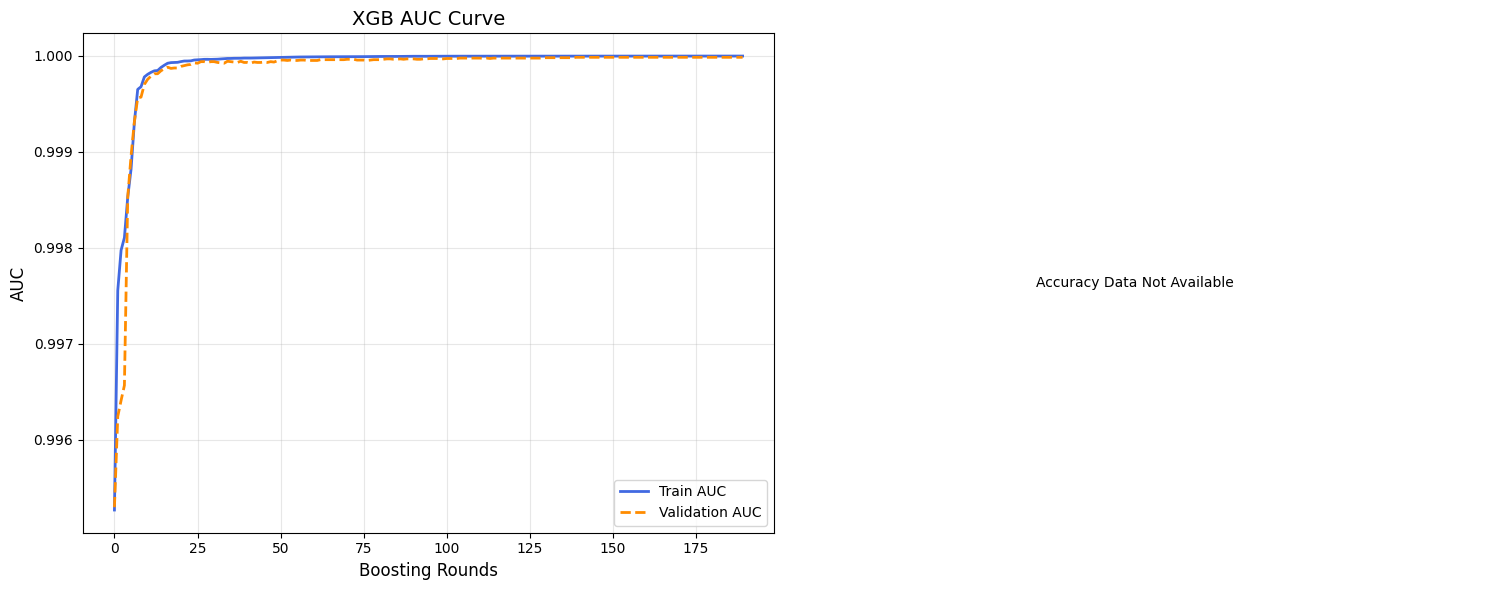


=== Training LGB ===
|   iter    |  target   | featur... | learni... | num_le... |
-------------------------------------------------------------
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[31]	valid_0's auc: 1
| 1         | 1.0       | 0.6873    | 0.2857    | 113.8     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[51]	valid_0's auc: 1
| 2         | 1.0       | 0.7993    | 0.05525   | 36.06     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[8]	valid_0's auc: 1
| 3         | 1.0       | 0.529     | 0.2612    | 96.15     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[195]	valid_0's auc: 1
| 4         | 1.0       | 0.854     | 0.01597   | 145.9     |
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[125]	valid_0's auc: 1
| 5         | 1

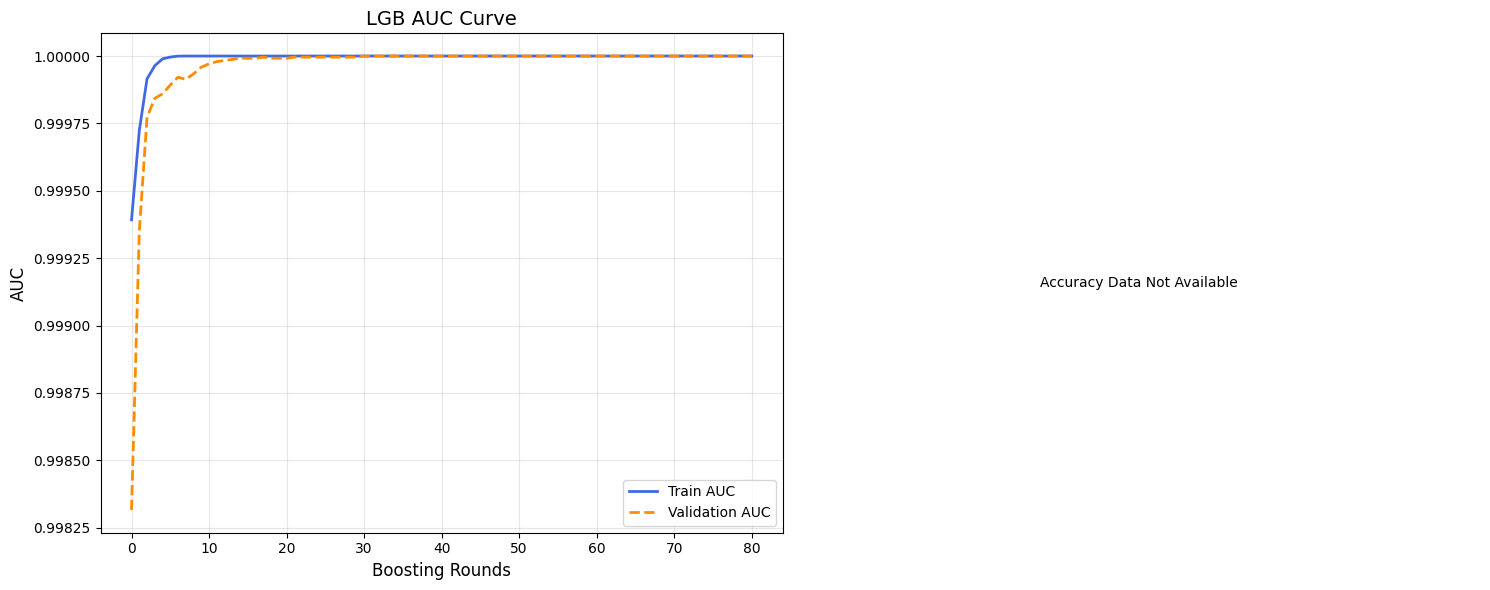


=== Training CAT ===
|   iter    |  target   |   depth   | l2_lea... | learni... |
-------------------------------------------------------------


D:\ProgramData\anaconda3\envs\ML\lib\site-packages\catboost\core.py:2321: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


| 1         | 0.9837    | 5.622     | 9.512     | 0.2223    |
| 2         | 0.9538    | 7.191     | 1.645     | 0.05524   |
| 3         | 0.9814    | 3.407     | 8.675     | 0.1843    |


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_30196\625952136.py:47: RuntimeWarning: overflow encountered in exp
  y_pred = 1 / (1 + np.exp(-np.array(approxes)))


| 4         | 0.9782    | 7.957     | 0.3038    | 0.2913    |
| 5         | 0.9254    | 8.827     | 2.202     | 0.06273   |


...

| 28        | 0.9853    | 5.612     | 0.9341    | 0.01      |


D:\ProgramData\anaconda3\envs\ML\lib\site-packages\catboost\core.py:2321: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_30196\625952136.py:47: RuntimeWarning: overflow encountered in exp
  y_pred = 1 / (1 + np.exp(-np.array(approxes)))


| 29        | 0.9977    | 4.594     | 0.1       | 0.3       |


D:\ProgramData\anaconda3\envs\ML\lib\site-packages\catboost\core.py:2321: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


| 30        | 0.9649    | 4.753     | 9.224     | 0.3       |
0:	test: 0.9888964	test1: 0.9874265	best: 0.9874265 (0)	total: 6.12ms	remaining: 6.12s
50:	test: 0.9982239	test1: 0.9989144	best: 0.9989185 (49)	total: 311ms	remaining: 5.78s
100:	test: 0.9985660	test1: 0.9991703	best: 0.9991703 (100)	total: 608ms	remaining: 5.41s
150:	test: 0.9989619	test1: 0.9994716	best: 0.9995170 (144)	total: 902ms	remaining: 5.07s
200:	test: 0.9986992	test1: 0.9996533	best: 0.9996533 (199)	total: 1.2s	remaining: 4.78s
250:	test: 0.9981142	test1: 0.9997565	best: 0.9997565 (248)	total: 1.5s	remaining: 4.49s
300:	test: 0.9963855	test1: 0.9997358	best: 0.9998019 (281)	total: 1.79s	remaining: 4.16s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9998018625
bestIteration = 281

Shrink model to first 282 iterations.


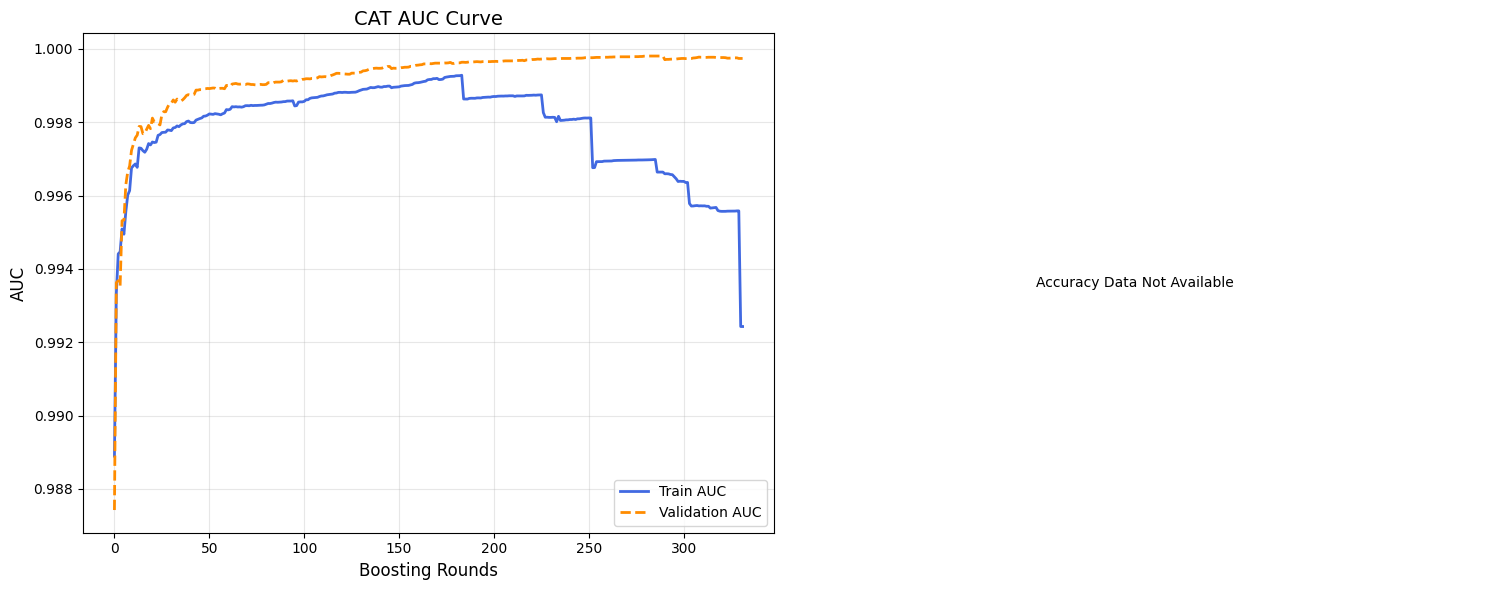


=== Training Stacking Model ===

=== Final Evaluation ===

xgb Performance:
Accuracy: 0.9970 | AUC: 0.9998 | F1: 0.9962
[[607   2]
 [  1 390]]

lgb Performance:
Accuracy: 0.9970 | AUC: 1.0000 | F1: 0.9962
[[608   1]
 [  2 389]]

cat Performance:
Accuracy: 0.9870 | AUC: 0.9962 | F1: 0.9835
[[599  10]
 [  3 388]]

Stacking Performance:
Stacking Model Performance:
Accuracy: 0.9970 | AUC: 1.0000 | F1: 0.9962
[[608   1]
 [  2 389]]


In [35]:

    # 训练基模型
    base_models = []
    for model_type in ['xgb', 'lgb', 'cat']:
        print(f"\n=== Training {model_type.upper()} ===")
        # 参数类型安全转换
        raw_params = optimize_model(model_type, X_train, y_train, X_val, y_val)
        
        # 统一处理参数类型
        if model_type == 'xgb':
            params = {
                'max_depth': int(round(raw_params['max_depth'])),
                'learning_rate': raw_params['learning_rate'],
                'subsample': raw_params['subsample'],
                'lambda': raw_params['reg_lambda']
            }
        elif model_type == 'lgb':
            params = {
                'num_leaves': int(round(raw_params['num_leaves'])),
                'learning_rate': raw_params['learning_rate'],
                'feature_fraction': raw_params['feature_fraction']
            }
        else:
            params = {
                'depth': int(round(raw_params['depth'])),
                'learning_rate': raw_params['learning_rate'],
                'l2_leaf_reg': raw_params['l2_leaf_reg']
            }
        
        model, history = train_model(model_type, X_train, y_train, 
                                   X_val, y_val, params)
        base_models.append(model)
        plot_enhanced_training_curves(history, model_type.upper())
    
    # 训练Stacking模型
    print("\n=== Training Stacking Model ===")
    stacking = StackingEnsemble(base_models)
    stacking.fit(X_train, y_train)
    
    # 模型评估
    print("\n=== Final Evaluation ===")
    model_names = ['xgb', 'lgb', 'cat', 'Stacking']
    all_models = base_models + [stacking]
    
    for name, model in zip(model_names, all_models):
        print(f"\n{name} Performance:")
        if name == 'Stacking':
            acc, auc, f1 = stacking.evaluate_stacking(X_test, y_test)
        else:
            acc, auc, f1 = evaluate_model(model, name.lower(), X_test, y_test)


In [21]:
import catboost
print(catboost.__version__ )

1.2.7
